In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anikannal/solar-power-generation-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'solar-power-generation-data' dataset.
Path to dataset files: /kaggle/input/solar-power-generation-data


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df_p1_G = pd.read_csv('/kaggle/input/solar-power-generation-data/Plant_1_Generation_Data.csv')

In [ ]:
df_p1_G.head()

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [ ]:
first_22 = set(df_p1_G['SOURCE_KEY'].head(22))
all_unique = set(df_p1_G['SOURCE_KEY'].unique())


In [ ]:
df_p1_w = pd.read_csv('/kaggle/input/solar-power-generation-data/Plant_1_Weather_Sensor_Data.csv')

df_p1_G['DATE_TIME'] = pd.to_datetime(
    df_p1_G['DATE_TIME'],
    format='%d-%m-%Y %H:%M'
)

In [ ]:
df_p1_w['DATE_TIME'] = pd.to_datetime(df_p1_w['DATE_TIME'])

df_p1_merged = pd.merge(df_p1_G, df_p1_w, on=['DATE_TIME'], how='left')

df = df_p1_merged[['AC_POWER', 'IRRADIATION',
                    'AMBIENT_TEMPERATURE', 'DC_POWER', 'DATE_TIME']]

df_plant = df.groupby('DATE_TIME').agg({
    'AC_POWER': 'sum',
    'DC_POWER': 'sum',
    'IRRADIATION': 'mean',
    'AMBIENT_TEMPERATURE': 'mean'
}).reset_index()

df_hourly = df_plant.resample('1H', on='DATE_TIME').mean().reset_index()

df_hourly.drop(labels=['DC_POWER'], axis=1, inplace=True, errors='ignore')

# Extract time features
df_hourly['HOUR'] = df_hourly['DATE_TIME'].dt.hour

df_hourly['HOUR_SIN'] = np.sin(2 * np.pi * df_hourly['HOUR'] / 24)
df_hourly['HOUR_COS'] = np.cos(2 * np.pi * df_hourly['HOUR'] / 24)

df_hourly = df_hourly.drop(columns=['HOUR'])

df_hourly = df_hourly[df_hourly['IRRADIATION'] > 0]

df = df_hourly.drop(columns=['DATE_TIME'])


df.to_csv('train.csv', index=False)

print("Preprocessing completed. Saved to data/processed/train.csv")

Preprocessing completed. Saved to data/processed/train.csv


/tmp/ipykernel_3676/422222676.py:15: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_hourly = df_plant.resample('1H', on='DATE_TIME').mean().reset_index()


In [ ]:
df.head()

,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,HOUR_SIN,HOUR_COS
5,0.000000,0.000216,24.274983,0.965926,2.588190e-01
6,1238.727679,0.043243,24.073951,1.000000,6.123234e-17
7,4262.353631,0.147561,24.889582,0.965926,-2.588190e-01
8,9110.836101,0.316280,26.160302,0.866025,-5.000000e-01
9,12302.173661,0.439623,27.644042,0.707107,-7.071068e-01


drift test csv


In [ ]:
df_p2_G = pd.read_csv('/kaggle/input/solar-power-generation-data/Plant_2_Generation_Data.csv')

first_22 = set(df_p2_G['SOURCE_KEY'].head(22))
all_unique = set(df_p2_G['SOURCE_KEY'].unique())

df_p2_w = pd.read_csv('/kaggle/input/solar-power-generation-data/Plant_2_Weather_Sensor_Data.csv')

df_p2_G['DATE_TIME'] = pd.to_datetime(
    df_p2_G['DATE_TIME'],
    format='%Y-%m-%d %H:%M:%S'
)

df_p2_w['DATE_TIME'] = pd.to_datetime(df_p2_w['DATE_TIME'])

df_p2_merged = pd.merge(df_p2_G, df_p2_w, on=['DATE_TIME'], how='left')

df = df_p2_merged[['AC_POWER', 'IRRADIATION',
                    'AMBIENT_TEMPERATURE', 'DC_POWER', 'DATE_TIME']]

df_plant = df.groupby('DATE_TIME').agg({
    'AC_POWER': 'sum',
    'DC_POWER': 'sum',
    'IRRADIATION': 'mean',
    'AMBIENT_TEMPERATURE': 'mean'
}).reset_index()

df_hourly = df_plant.resample('1h', on='DATE_TIME').mean().reset_index()

df_hourly.drop(labels=['DC_POWER'], axis=1, inplace=True, errors='ignore')

# Extract time features
df_hourly['HOUR'] = df_hourly['DATE_TIME'].dt.hour

df_hourly['HOUR_SIN'] = np.sin(2 * np.pi * df_hourly['HOUR'] / 24)
df_hourly['HOUR_COS'] = np.cos(2 * np.pi * df_hourly['HOUR'] / 24)

df_hourly = df_hourly.drop(columns=['HOUR'])

df_hourly = df_hourly[df_hourly['IRRADIATION'] > 0]

df = df_hourly.drop(columns=['DATE_TIME'])


df.to_csv('validation.csv', index=False)

print("Preprocessing completed. Saved to validation.csv")

Preprocessing completed. Saved to validation.csv


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 469 entries, 0 to 468
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   AC_POWER             469 non-null    float64
 1   IRRADIATION          469 non-null    float64
 2   AMBIENT_TEMPERATURE  469 non-null    float64
 3   HOUR_SIN             469 non-null    float64
 4   HOUR_COS             469 non-null    float64
dtypes: float64(5)
memory usage: 18.4 KB


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Load the training data
train_df = pd.read_csv('train.csv')

# Define features and target
X = train_df.drop(columns=['AC_POWER'])
y = train_df['AC_POWER']

# Split into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)
    results[name] = {'RMSE': rmse, 'R2': r2}

# Display the comparison table
results_df = pd.DataFrame(results).T
display(results_df)

,RMSE,R2
Linear Regression,496.770642,0.996732
Random Forest Regressor,548.487723,0.996016
Gradient Boosting Regressor,523.095215,0.996377


In [ ]:
from sklearn.model_selection import cross_validate

# Perform 5-fold cross-validation for each model
cv_results = {}
scoring = ['neg_mean_squared_error', 'r2']

for name, model in models.items():
    scores = cross_validate(model, X, y, cv=5, scoring=scoring, return_train_score=False)

    # Calculate mean metrics from cross-validation
    rmse_scores = np.sqrt(-scores['test_neg_mean_squared_error'])
    mean_rmse = np.mean(rmse_scores)
    std_rmse = np.std(rmse_scores)
    mean_r2 = np.mean(scores['test_r2'])
    std_r2 = np.std(scores['test_r2'])

    cv_results[name] = {
        'CV Mean RMSE': mean_rmse,
        'CV RMSE Std': std_rmse,
        'CV Mean R2': mean_r2,
        'CV R2 Std': std_r2
    }

# Display the cross-validation performance comparison
cv_results_df = pd.DataFrame(cv_results).T
display(cv_results_df)

,CV Mean RMSE,CV RMSE Std,CV Mean R2,CV R2 Std
Linear Regression,654.147049,163.078534,0.993050,0.003675
Random Forest Regressor,661.111702,114.903043,0.993121,0.002626
Gradient Boosting Regressor,627.613143,137.274228,0.993689,0.002856


### Model Performance Summary

Based on the 5-fold cross-validation results:

1. **Gradient Boosting Regressor** is the **best performing model** overall:
   - **Lowest CV Mean RMSE:** ~627.61
   - **Highest CV Mean $R^2$:** ~0.9937

2. **Linear Regression** performs exceptionally well and is highly competitive:
   - **CV Mean RMSE:** ~654.15
   - **CV Mean $R^2$:** ~0.9931
   - *Advantage:* Extremely fast to train and highly interpretable.

3. **Random Forest Regressor**:
   - **CV Mean RMSE:** ~661.11
   - **CV Mean $R^2$:** ~0.9931

**Conclusion:** We should select the **Gradient Boosting Regressor** as our final model for predicting `AC_POWER` due to its superior error minimization and accuracy.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt


pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GradientBoostingRegressor(random_state=42))
])

pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print(f"RMSE: {rmse}")
print(f"R2 Score: {r2}")



RMSE: 523.1008687264176
R2 Score: 0.9963766551780785


In [24]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
})

print(results.head(10))

         Actual     Predicted
0   3096.951339   3070.696163
1   6402.783929   6432.880102
2  17692.664732  17995.623080
3  11403.921429  11224.951900
4   2699.058929   2765.666536
5   4728.608036   4601.297784
6  17975.581250  17843.438515
7  19202.965982  18758.401911
8  21207.922767  21879.166269
9      0.434375    126.123046


In [25]:
results["Error"] = results["Actual"] - results["Predicted"]

print(results.head(10))

         Actual     Predicted       Error
0   3096.951339   3070.696163   26.255176
1   6402.783929   6432.880102  -30.096174
2  17692.664732  17995.623080 -302.958347
3  11403.921429  11224.951900  178.969529
4   2699.058929   2765.666536  -66.607607
5   4728.608036   4601.297784  127.310252
6  17975.581250  17843.438515  132.142735
7  19202.965982  18758.401911  444.564071
8  21207.922767  21879.166269 -671.243502
9      0.434375    126.123046 -125.688671


In [26]:
print(results["Error"].describe())

count      94.000000
mean       66.295825
std       521.665055
min     -1891.358434
25%       -65.835968
50%        17.823131
75%       268.265109
max      1776.492093
Name: Error, dtype: float64


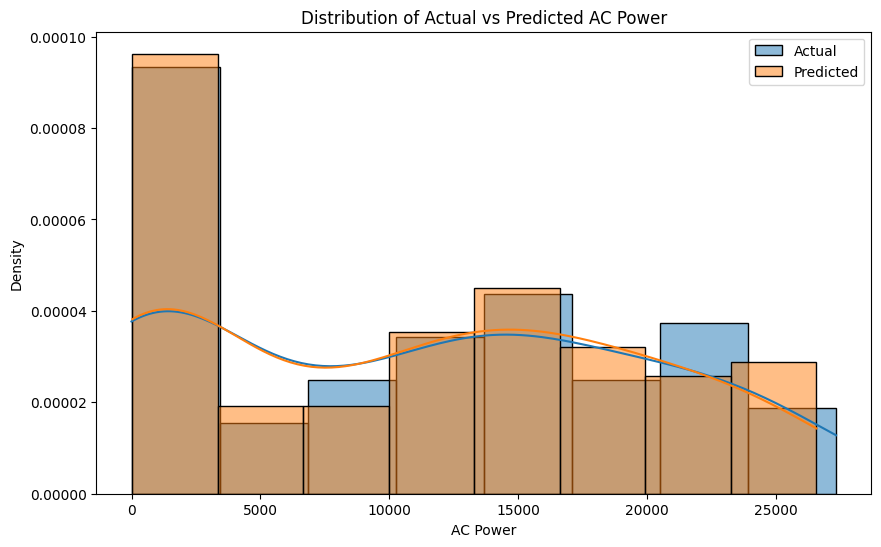

In [27]:
plt.figure(figsize=(10, 6))

sns.histplot(y_test, kde=True, label="Actual", stat="density")
sns.histplot(predictions, kde=True, label="Predicted", stat="density")

plt.xlabel("AC Power")
plt.ylabel("Density")
plt.title("Distribution of Actual vs Predicted AC Power")
plt.legend()
plt.show()

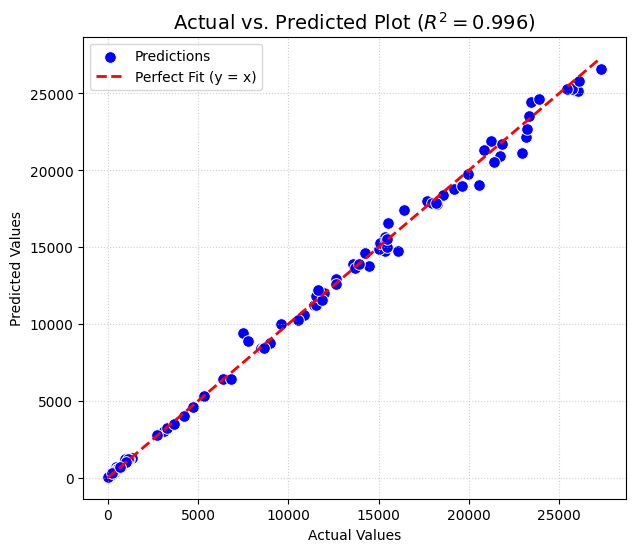

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import r2_score

# Sample values
y_true = y_test
y_pred = predictions

# Calculate R-squared score
r2 = r2_score(y_true, y_pred)

plt.figure(figsize=(7, 6))

# Scatter plot of actual vs predicted
sns.scatterplot(x=y_true, y=y_pred, color="blue", s=70, label="Predictions")

# Draw the 45-degree reference line for ideal predictions
min_val = min(min(y_true), min(y_pred))
max_val = max(max(y_true), max(y_pred))
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit (y = x)",
)

plt.title(f"Actual vs. Predicted Plot ($R^2 = {r2:.3f}$)", fontsize=14)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [ ]:
import joblib

# Exporting the pipeline
joblib.dump(pipeline, "model_pipeline.joblib", compress=3)

# Loading in production
loaded_pipeline = joblib.load("model_pipeline.joblib")

In [ ]:
import numpy as np
import pandas as pd

def calculate_psi(expected, actual, num_buckets=10):
    # Sort expected distribution to determine quantile boundaries
    percentiles = np.linspace(0, 100, num_buckets + 1)
    # Get boundaries ignoring duplicate edges (using unique)
    boundaries = np.percentile(expected, percentiles)
    boundaries = np.unique(boundaries)

    # If the feature has too few unique values, use uniform binning instead
    if len(boundaries) < 2:
        boundaries = np.linspace(min(expected), max(expected), num_buckets + 1)
        boundaries = np.unique(boundaries)

    # Add outer boundaries to make sure all points fall inside
    boundaries[0] = -np.inf
    boundaries[-1] = np.inf

    # Calculate counts in each bucket
    expected_counts, _ = np.histogram(expected, bins=boundaries)
    actual_counts, _ = np.histogram(actual, bins=boundaries)

    # Convert counts to percentages (avoid division by zero)
    expected_pct = expected_counts / len(expected)
    actual_pct = actual_counts / len(actual)

    # Handle zero counts using a small epsilon adjustment to avoid log(0) errors
    expected_pct = np.where(expected_pct == 0, 0.0001, expected_pct)
    actual_pct = np.where(actual_pct == 0, 0.0001, actual_pct)

    # Calculate PSI formula: (Actual - Expected) * ln(Actual / Expected)
    psi_value = np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct))
    return psi_value

def get_drift_status(psi):
    if psi < 0.10:
        return "Little/No Drift (PSI < 0.10)"
    elif 0.10 <= psi <= 0.25:
        return "Moderate Drift (0.10 <= PSI <= 0.25)"
    else:
        return "Significant Drift (PSI > 0.25)"

# Load files
train_df = pd.read_csv('train.csv')
validation_df = pd.read_csv('validation.csv')

features = ['IRRADIATION', 'AMBIENT_TEMPERATURE']

print("=== Population Stability Index (PSI) Analysis ===\n")
for feature in features:
    psi_val = calculate_psi(train_df[feature], validation_df[feature], num_buckets=10)
    status = get_drift_status(psi_val)
    print(f"Feature: {feature}")
    print(f"  - PSI Value: {psi_val:.4f}")
    print(f"  - Drift Status: {status}\n")

=== Population Stability Index (PSI) Analysis ===

Feature: IRRADIATION
  - PSI Value: 0.1142
  - Drift Status: Moderate Drift (0.10 <= PSI <= 0.25)

Feature: AMBIENT_TEMPERATURE
  - PSI Value: 0.5993
  - Drift Status: Significant Drift (PSI > 0.25)

